# Day 2 - Supervised learning practical tasks
***
These tasks cover linear regression, logistic regression, decision trees, model evaluation and regularization.

## Regression models

You will use [Advertising](https://www.kaggle.com/purbar/advertising-data) Dataset. The dataset contains statistics about the sales of a product in 200 different markets, together with advertising budgets in each of these markets for different media channels: TV, radio and newspaper.
#### Your task will be to:
1. Write evaluation functions (MAE, MSE, SSE, RMSE, MAPE, R2).
2. Analyze the correlation matrix.
3. Predict sales values using linear regression.
4. Evaluate model with written statistical explanatory variables.
5. Perform cross-validation (k-fold).
6. Compare your regression model to a reduced model by removing one of the features.
7. Compare your regression model to regularization models.

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

In [3]:
import numpy as np
import pandas as pd

# Data
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_regression

# Models
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Model evaluation
from sklearn.metrics import accuracy_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

### 1. Create statistical evaluation functions for regression models

#### 1.1 Create a function that calculates mean absolute error (MAE)

\begin{equation}
MAE = \frac{1}{n} \sum_{i=1}^{n} \left| y_i - \hat{y}_i\right|
\end{equation}

In [4]:
def MAE(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    n = len(y_true)
    total = 0
    for i in range(n):
        total += abs(y_true[i] - y_pred[i])
    result = total / n
    return result

In [5]:
print(MAE([3, 5, 2], [2, 7, 2]))

1.0


#### 1.2 Create a function that calculates mean squared error (MSE)

\begin{equation}
MSE = \frac{1}{n}\cdot SSE
\end{equation}

\begin{equation}
SSE = \sum_{i=1}^n(y_i - \hat{y}_i)^2
\end{equation}

In [6]:
def MSE(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    n = len(y_true)
    SSE = 0
    for i in range(n):
        SSE += (y_true[i] - y_pred[i])**2
    result = 1/n * SSE
    return result

In [7]:
print(MSE([3, 5, 2], [2, 7, 2]))


1.6666666666666665


#### 1.3 Create a function that calculates root mean squared error (RMSE)

\begin{equation}
RMSE = \sqrt{MSE}
\end{equation}

In [8]:
def RMSE(y_true, y_pred):
    return np.sqrt(MSE(y_true, y_pred))

In [9]:
print(RMSE([3, 5, 2], [2, 7, 2]))


1.2909944487358056


#### 1.4 Create a function that calculates mean absolute percentage error (MAPE)

\begin{equation}
MAPE = \frac{100}{n} \sum_{i=1}^n \left| \frac{y_i - \hat{y}_i}{y_i} \right|
\end{equation}

In [10]:
def MAPE(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    n = len(y_true)
    total = 0
    for i in range(n):
        total += abs((y_true[i] - y_pred[i]) / y_true[i])
    result = 100/n * total
    return result

In [11]:
print(MAPE([3, 5, 2], [2, 7, 2]))

24.444444444444446


#### 1.5 Create a function that calculates coefficient of determination $R^2$ using formula

\begin{equation}
R^2 = \frac{SST-SSE}{SST}
\end{equation}

\begin{equation}
SST = \sum_{i=1}^n (y_i - \bar{y})^2
\end{equation}


In [12]:
def R2(y_true, y_pred):
    y_true = np.array(y_true)
    y_mean = np.mean(y_true)
    y_pred = np.array(y_pred)
    n = len(y_true)

    SSE = 0
    for i in range(n):
        SSE += (y_true[i] - y_pred[i])**2

    SST = 0
    for i in range(n):
        SST += (y_true[i] - y_mean)**2
    result = (SST - SSE) / SST
    return result

In [13]:
print(R2([3, 5, 2], [2, 7, 2]))

-0.07142857142857156


### 2 Use Linear regression model to make predictions and evaluate it with above developed functions. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling - split the data in target variable and features.

In [14]:
df = pd.read_csv("advertising.csv", index_col = 0)
df.head()

,TV,Radio,Newspaper,Sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


In [15]:
x = df.drop(columns=["Sales"])
y = df["Sales"]

In [16]:
print(x.head())
print(y.head())

      TV  Radio  Newspaper
1  230.1   37.8       69.2
2   44.5   39.3       45.1
3   17.2   45.9       69.3
4  151.5   41.3       58.5
5  180.8   10.8       58.4
1    22.1
2    10.4
3     9.3
4    18.5
5    12.9
Name: Sales, dtype: float64


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

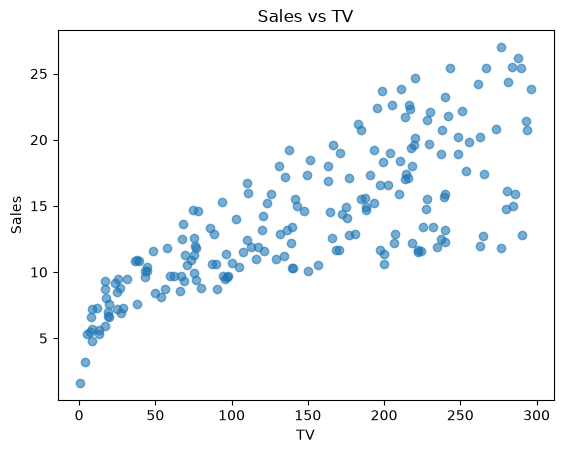

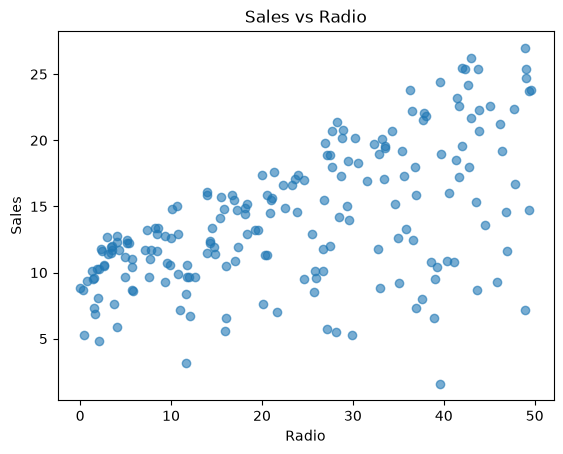

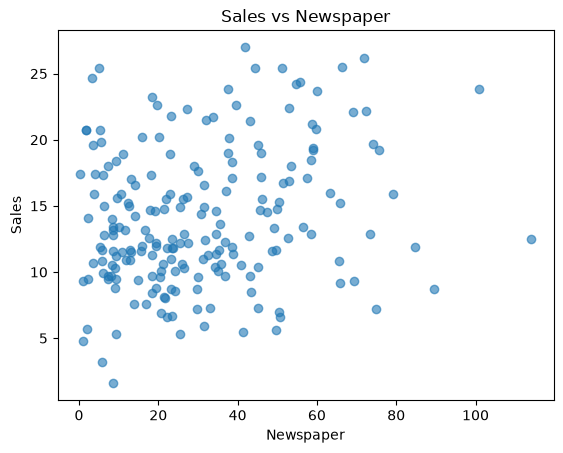

In [17]:
for col in ['TV', 'Radio', 'Newspaper']:
    plt.scatter(df[col], df['Sales'], alpha=0.6)
    plt.xlabel(col)
    plt.ylabel('Sales')
    plt.title(f'Sales vs {col}')
    plt.show()

TV advertising cost has strong positive corelation with sales.
Radio advertising cost has positive but weaker corelation with sales.
Newspaper advertising cost seem to have weak relationship with sales. Pattern is cloudy and random. 

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler).

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=17)

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("x_train:", x_train[:5])
print("x_test:", x_test[:5])
print("x_train_scaled:", x_train_scaled[:5])
print("x_test_scaled:", x_test_scaled[:5])

x_train:         TV  Radio  Newspaper
116   75.1   35.0       52.7
199  283.6   42.0       66.2
156    4.1   11.6        5.7
194  166.8   42.0        3.6
89    88.3   25.5       73.4
x_test:         TV  Radio  Newspaper
1    230.1   37.8       69.2
147  240.1    7.3        8.7
159   11.7   36.9       45.2
177  248.4   30.2       20.3
198  177.0    9.3        6.4
x_train_scaled: [[-0.80495724  0.78669162  1.0228264 ]
 [ 1.56429998  1.25287189  1.66127675]
 [-1.61175467 -0.77168241 -1.19992667]
 [ 0.2370614   1.25287189 -1.29924117]
 [-0.6549611   0.15401841  2.0017836 ]]
x_test_scaled: [[ 0.95636108  0.97316373  1.8031546 ]
 [ 1.06999452 -1.05805028 -1.05804881]
 [-1.52539325  0.91322627  0.66813176]
 [ 1.16431028  0.46702515 -0.50945444]
 [ 0.35296751 -0.92485592 -1.16682183]]


#### 2.4 Fit linear regression model, generate predictions and print regression coefficients $b_0$ and $b_1$.

In [19]:
model = LinearRegression()
model.fit(x_train_scaled, y_train)

y_pred = model.predict(x_test_scaled)

print("b0 (intercept):", model.intercept_)
print("b1 (coefficients):", model.coef_)

b0 (intercept): 14.022388059701495
b1 (coefficients): [ 3.9675339   2.88155345 -0.07344038]


In [20]:
for name, coef in zip(x_train.columns, model.coef_):
    print(f"{name}: {coef:.3f}")

TV: 3.968
Radio: 2.882
Newspaper: -0.073


#### 2.5 Evaluate created model with above functions

In [21]:
print("MAE score:", MAE(y_test, y_pred))
print("MSE score:", MSE(y_test, y_pred))
print("RMSE score:", RMSE(y_test, y_pred))
print("MAPE score:", MAPE(y_test, y_pred))
print("R^2 score:", R2(y_test, y_pred))

MAE score: 1.2414902596508468
MSE score: 3.472629968752789
RMSE score: 1.863499387913178
MAPE score: 18.638804594568974
R^2 score: 0.8515370160992793


#### 2.6 Perform k-fold cross-validation $(k=10)$ and print the mean $R^2$ score to get an overall performance metric.

Please use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [r2](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules) score.

In [22]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

pipe = make_pipeline(StandardScaler(), LinearRegression())
scores = cross_val_score(pipe, x, y, cv=10, scoring='r2')

print("R² per fold:", scores.round(3))
print("Mean R²:", scores.mean())

R² per fold: [0.873 0.858 0.93  0.89  0.931 0.931 0.76  0.912 0.839 0.929]
Mean R²: 0.8853562237979616


#### 2.7. Drop one of the three variables (TV, Radio or Newspaper) and create another model, evaluate it and compare to the first model.

In [23]:
x2 = x.drop(columns=["Newspaper"])

x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y, test_size=0.33, random_state=17)

scaler2 = StandardScaler()
x2_train_scaled = scaler2.fit_transform(x2_train)
x2_test_scaled = scaler2.transform(x2_test)

model2 = LinearRegression()
model2.fit(x2_train_scaled, y2_train)
y2_pred = model2.predict(x2_test_scaled)

print("MAE:", MAE(y2_test, y2_pred))
print("MSE:", MSE(y2_test, y2_pred))
print("RMSE:", RMSE(y2_test, y2_pred))
print("MAPE:", MAPE(y2_test, y2_pred))
print("R²:", R2(y2_test, y2_pred))

MAE: 1.2423619953941774
MSE: 3.4587409987632234
RMSE: 1.859769071353544
MAPE: 18.594637663112877
R²: 0.8521308017736854


In [24]:
scores2 = cross_val_score(pipe, x2, y, cv=10, scoring='r2')
print("Mean R² (dropped newspaper):", scores2.mean())
print("Mean R² (with all):", scores.mean())

Mean R² (dropped newspaper): 0.8869670516810129
Mean R² (with all): 0.8853562237979616


### 3. Use regularization models with regularization strength `alpha=1` and compare $MSE$ values with previous models.

#### 3.1 Lasso regression

In [25]:
lasso = Lasso(alpha=1)
lasso.fit(x_train, y_train)

y_pred = lasso.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {MSE}")
print("Coefficients:", lasso.coef_)

Mean Squared Error: <function MSE at 0x7f9f1f793110>
Coefficients: [ 0.04495034  0.18603609 -0.        ]


#### 3.2 Ridge regression

In [26]:
ridge = Ridge(alpha=1.0)
ridge.fit(x_train, y_train)
y_pred = ridge.predict(x_test)

mse = mean_squared_error(y_test, y_pred)
print("Mean Squared Error:", mse)
print("Coefficients:", ridge.coef_)

Mean Squared Error: 3.472602331756184
Coefficients: [ 0.04508449  0.19189626 -0.00347159]


#### 3.3 Elastic net regression

Use any `l1_ratio` of your choice.


In [27]:
elastic_net = ElasticNet(alpha=1.0, l1_ratio=0.5)
elastic_net.fit(x_train, y_train)

y_pred = elastic_net.predict(x_test)
mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)
print("Coefficients:", elastic_net.coef_)

Mean Squared Error: 3.4582606829611677
Coefficients: [ 0.04501785  0.18847258 -0.00155555]


#### 3.4 Make conclusions

All 4 perform almost exactly the same with very small MSE difference

## Classification models

You will use [Diabetes](https://www.kaggle.com/uciml/pima-indians-diabetes-database) dataset. The dataset includes data from 768 women with several medical predictor variables and one target variable. The classification goal is to predict whether or not the patients in the dataset have diabetes.
#### Your task will be to:
1. Write evaluation functions (Accuracy, Precision, Recall, F1).
2. Predict whether or not a patient has diabetes using Logistic regression and Decision Tree Classification models
3. Evaluate both models with written statistical explanatory variables
4. Draw ROC curve and compute AUC
5. Perform cross-validation (k-fold)
6. Analyze the results

Please use your code and visualization results made in previous day for data preparation and explanatory analysis.

### 1. Write statistical evaluation functions for classification models

#### 1.1 Create a function that calculates accuracy

\begin{equation}
Accuracy = \frac{True Positive + True Negative}{True Positive + True Negative + False Positive + False Negative}
\end{equation}

In [28]:
def accuracy (TP, TN, FP, FN):
    return (TP + TN) / (TP + TN + FP + FN)

#### 1.2 Create a function that calculates precision

\begin{equation}
Precision = \frac{True Positive}{True Positive + False Positive}
\end{equation}

In [29]:
def precision(TP, FP):
    return TP / (TP + FP)

#### 1.3  Create a function that calculates recall

\begin{equation}
Recall = \frac{True Positive}{True Positive + False Negative}
\end{equation}

In [30]:
def recall(TP, FN):
    return TP / (TP + FN)

#### 1.4 Create a function that calculates $F1$ - score

\begin{equation}
F1 = 2\cdot \frac{Precision \cdot Recall}{Precision + Recall}
\end{equation}

In [31]:
def F1(TP, FP, FN):
    p = precision(TP, FP)
    r = recall(TP, FN)
    return 2 * p * r / (p + r)

### 2. Use logistic regression to make prediction and evaluate it with above developed functions. Compute ROC and compute AUC. Perform k-fold cross-validation.

#### 2.1 Read and prepare dataset for modelling. Split the data in target variable and features.

Prepare dataset to use it for modelling (you should also replace 0 values in columns `Glucose`, `BloodPressure`,`SkinThickness`,`Insulin`,`BMI` with mean values).

In [32]:
df_c = pd.read_csv("diabetes.csv")
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_c[cols] = df_c[cols].replace(0, np.nan)
df_c[cols] = df_c[cols].fillna(df_c[cols].mean())
df_c.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


#### 2.2. Look at the correlation and visualize the data by methods from day 1 by plots of your choice. Write what you observe.

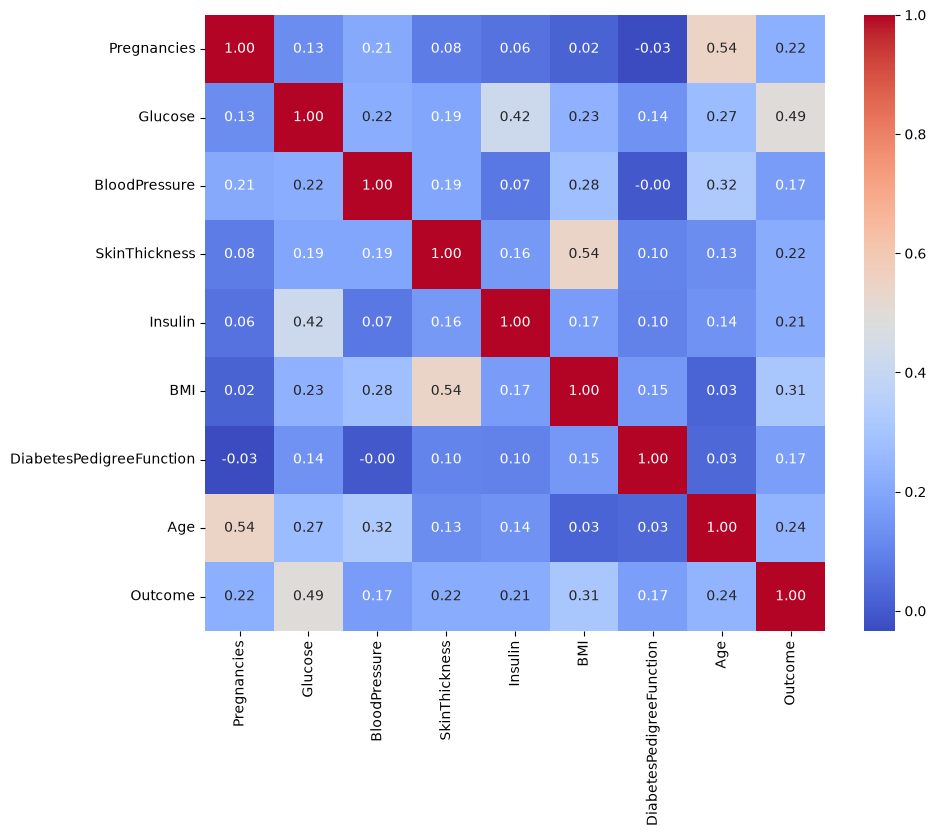

In [33]:
plt.figure(figsize=(10, 8))
sns.heatmap(df_c.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

Glucose is linked the most with outcome (0.49), followed by BMI (0.31) and Age (0.24) but with almost half the value of either.

#### 2.3 Separate the target feature, split data in 2:1 proportion (33% form a holdout set, use random_state=17), and preprocess data with [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

In [34]:
x_c = df_c.drop(columns=["Outcome"])
y_c = df_c["Outcome"]

x_train_c, x_test_c, y_train_c, y_test_c = train_test_split(x_c, y_c, test_size=0.33, random_state=17)

scaler_c = StandardScaler()
x_train_c_scaled = scaler_c.fit_transform(x_train_c)
x_test_c_scaled = scaler_c.transform(x_test_c)
print(x_train_c_scaled.shape, x_test_c_scaled.shape)

(514, 8) (254, 8)


#### 2.4 Fit logistic regression model, generate predictions

In [35]:
log_model = LogisticRegression()
log_model.fit(x_train_c_scaled, y_train_c)
y_pred_log = log_model.predict(x_test_c_scaled)

print(y_pred_log[:20])
print(np.array(y_test_c[:20]))

[0 1 0 0 0 0 0 1 1 1 1 1 0 0 0 0 1 0 0 0]
[0 1 0 0 0 0 0 1 1 1 0 1 0 0 0 1 1 0 0 1]


#### 2.5 Create a confusion matrix and evaluate created model with above functions

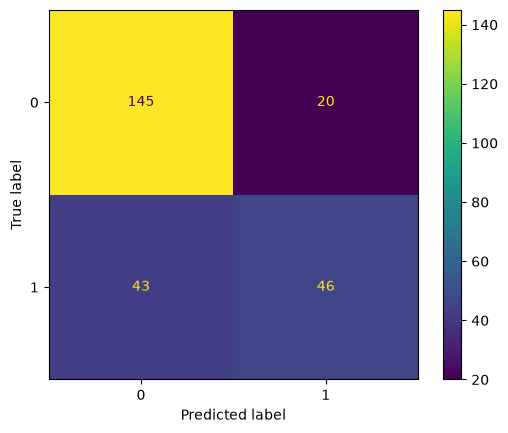

Accuracy: 0.7519685039370079
Precision: 0.696969696969697
Recall: 0.5168539325842697
F1: 0.5935483870967742


In [36]:
cm = confusion_matrix(y_test_c, y_pred_log)
ConfusionMatrixDisplay(cm).plot()
plt.show()

TN, FP, FN, TP = cm.ravel()

print("Accuracy:", accuracy(TP, TN, FP, FN))
print("Precision:", precision(TP, FP))
print("Recall:", recall(TP, FN))
print("F1:", F1(TP, FP, FN))

#### 2.6 Draw a ROC curve and compute Area Under the Curve (AUC)

You can use [roc_auc_score](http://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html) and [RocCurveDisplay.from_predictions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html#sklearn.metrics.RocCurveDisplay.from_predictions).
Check documentation for examples.
For roc_auc_score use predicted probabilities (`predict_proba`), not predicted values. This will align your AUC and ROC curve values.

`predict_proba()` method returns a two-dimensional array. For each instance the predicted class is the class with the maximum probability. To calculate AUC correctly, you need the probability of the positive class (second column, `[:, 1]`).

AUC: 0.8311201906707525


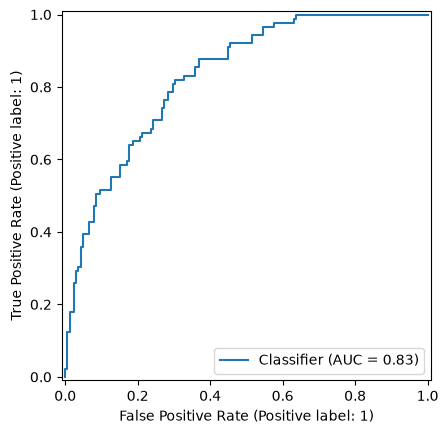

In [37]:
y_prob_log = log_model.predict_proba(x_test_c_scaled)[:, 1]
print("AUC:", roc_auc_score(y_test_c, y_prob_log))
RocCurveDisplay.from_predictions(y_test_c, y_prob_log)
plt.show()

#### 2.7 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

Use [cross_val_score](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html)
with [accuracy](https://scikit-learn.org/stable/modules/model_evaluation.html#the-scoring-parameter-defining-model-evaluation-rules). Feed your scaled X train and y train data.

In [38]:
scores_log = cross_val_score(LogisticRegression(), x_train_c_scaled, y_train_c, cv=10, scoring="accuracy")
print("CV accuracy:", scores_log.mean())

CV accuracy: 0.764630467571644


### 3. Use Decision tree classification model to make predictions and evaluate it with above developed functions. Draw ROC curve and compute AUC. Perform k-fold cross-validation.

#### 3.1 Create classification tree object, fit model and generate predictions

In [39]:
tree_model = DecisionTreeClassifier(random_state=17)
tree_model.fit(x_train_c_scaled, y_train_c)
y_pred_tree = tree_model.predict(x_test_c_scaled)

#### 3.2 Evaluate created model with above functions

In [40]:
cm_tree = confusion_matrix(y_test_c, y_pred_tree)
TN, FP, FN, TP = cm_tree.ravel()

print("Accuracy:", accuracy(TP, TN, FP, FN))
print("Precision:", precision(TP, FP))
print("Recall:", recall(TP, FN))
print("F1:", F1(TP, FP, FN))

Accuracy: 0.7755905511811023
Precision: 0.6666666666666666
Recall: 0.7191011235955056
F1: 0.6918918918918919


#### 3.3 Draw a ROC curve and compute Area Under the Curve (AUC)

AUC: 0.7625808648280558


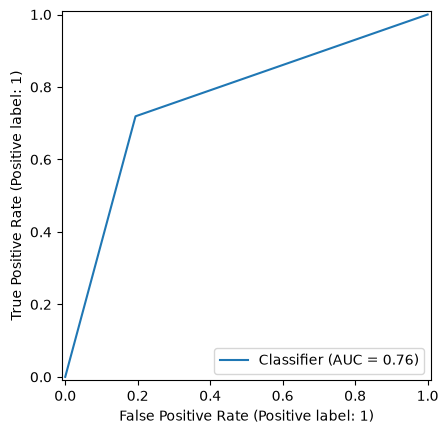

In [41]:
y_prob_tree = tree_model.predict_proba(x_test_c_scaled)[:, 1]
print("AUC:", roc_auc_score(y_test_c, y_prob_tree))
RocCurveDisplay.from_predictions(y_test_c, y_prob_tree)
plt.show()

#### 3.4 Perform k-fold cross-validation $(k=10)$ and print the mean accuracy to get an overall performance metric.

In [42]:
scores_tree = cross_val_score(DecisionTreeClassifier(random_state=17), x_train_c_scaled, y_train_c, cv=10, scoring="accuracy")
print("CV accuracy:", scores_tree.mean())

CV accuracy: 0.7257541478129713


#### 3.5 Make conclusions

I can't tell which model performed the best, both had their fall offs (perhaps I did something wrong). 
Logistics had better precision (by 0.03), AUC (by 0.068) and CV accuracy (0.039).
Tree had better Accuracy (by 0.024), Recall (by 0.2) and F1 (by 0.098).
Logistics seemed to have missed more sick people but it had higher CV accuracy, so perhaps over more data and testing it would be more reliable compared to tree. But both perfomred way under what I would expect acceptable. /TL;DR never trust a computer to replace a doctor/